# Classical pricing and risk references

Explore a European call under constant-parameter GBM. The notebook compares analytical prices and Greeks with independent Monte Carlo estimates, then examines parameter sensitivity, sampling uncertainty and spot-bump effects.

Change the inputs below and **Run All** from a fresh kernel. All pricing, payoff and simulation calculations call `bsde_pricing`; the notebook organises experiments and presentation. The detailed derivations are in the [methodology](../docs/methodology.md).

In [1]:
from pathlib import Path
import html
import os
import platform
from dataclasses import replace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import HTML, display

# Support kernels launched from either the repository root or notebooks/.
cwd = Path.cwd()
root = next((p for p in (cwd, cwd.parent) if (p / "bsde_pricing").is_dir()), None)
if root is None:
    raise RuntimeError("Open the deep-bsde-pricing repository folder and restart the kernel.")
os.chdir(root)

from bsde_pricing.problems import GBMModel, EuropeanCall, PricingCase
from bsde_pricing.black_scholes import BlackScholesReference
from bsde_pricing.monte_carlo import MonteCarloPricer

%matplotlib inline
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.2, "font.size": 10})

def table(headers, rows):
    heading = "".join(f"<th>{html.escape(str(v))}</th>" for v in headers)
    body = "".join("<tr>" + "".join(
        f"<td>{html.escape(format(v, '.7g') if isinstance(v, (float, np.floating)) else str(v))}</td>"
        for v in row) + "</tr>" for row in rows)
    display(HTML(f"<table><thead><tr>{heading}</tr></thead><tbody>{body}</tbody></table>"))

table(["Execution", "Version"], [("Python", platform.python_version()),
      ("NumPy", np.__version__), ("Matplotlib", matplotlib.__version__)])

Execution,Version
Python,3.12.14
NumPy,2.3.5
Matplotlib,3.10.8


## 1. Editable inputs

Rates use continuous compounding, maturity is in years, and volatility is annualised. Start by changing one financial input at a time. Seed and sample count control the numerical experiment rather than the option's economics.

The kernel must be the project's `bsde-pricing` environment. The default configuration is the previously verified vanilla case. The cells also work for other strictly positive spots/strikes and ordinary positive volatility/maturity settings.

In [2]:
spot = 100.0
strike = 100.0
rate = 0.03
dividend = 0.0
volatility = 0.20
maturity = 1.0

mc_paths = 100_000
seed = 2026
bump_fraction = 0.001
sample_counts = (1_000, 10_000, 100_000)
study_seeds = (2026, 2027, 2028, 2029)

case = PricingCase(
    "notebook_vanilla",
    GBMModel(rate, (volatility,), (dividend,), ((1.0,),)),
    EuropeanCall(strike, maturity), (spot,),
)
if volatility <= 0 or maturity <= 0:
    raise ValueError("The curve and delta studies require positive volatility and maturity.")
reference = BlackScholesReference(case.model, case.contract)
pricer = MonteCarloPricer(case.model, case.contract)
spot_grid = np.linspace(0.6 * strike, 1.4 * strike, 81)
base = reference.evaluate(spot)
table(["Input", "Value"], [("Spot", spot), ("Strike", strike), ("Rate", rate),
      ("Dividend yield", dividend), ("Volatility", volatility), ("Maturity", maturity),
      ("Monte Carlo samples", mc_paths), ("Seed", seed)])
table(["Call price", "Put price", "Call delta", "Gamma"],
      [(base.call_price, base.put_price, base.call_delta, base.gamma)])

Input,Value
Spot,100
Strike,100
Rate,0.03
Dividend yield,0
Volatility,0.2
Maturity,1
Monte Carlo samples,100000
Seed,2026


Call price,Put price,Call delta,Gamma
9.413403,6.457957,0.5987063,0.01933341


## 2. Price, delta and gamma across spot

Each curve holds contract and model parameters fixed while changing spot. Delta is the price slope; gamma is its curvature. The strike identifies the terminal-payoff kink, while a positive-volatility pre-expiry price is smooth.

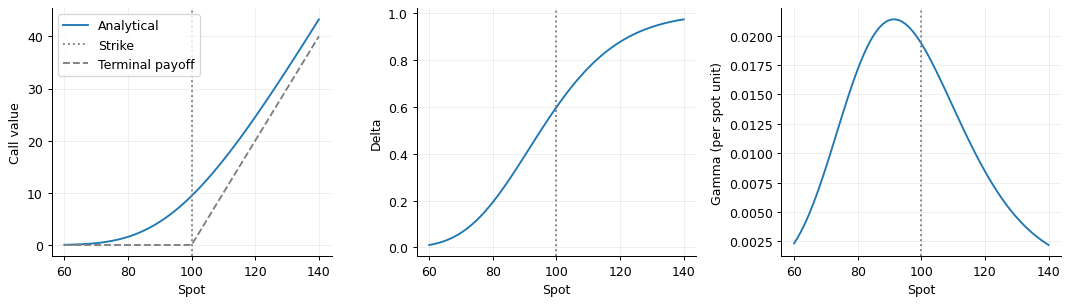

In [3]:
curve = [reference.evaluate(float(s)) for s in spot_grid]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, field, label in zip(axes, ("call_price", "call_delta", "gamma"),
                            ("Call value", "Delta", "Gamma (per spot unit)")):
    ax.plot(spot_grid, [getattr(v, field) for v in curve], color="C0", label="Analytical")
    ax.axvline(strike, color="0.5", ls=":", label="Strike")
    ax.set(xlabel="Spot", ylabel=label)
axes[0].plot(spot_grid, case.contract.payoff(spot_grid[:, None]),
             color="0.5", ls="--", label="Terminal payoff")
axes[0].legend()
fig.tight_layout()
plt.show()

## 3. Volatility, maturity, rates and dividends

The following grids are editable. They are selected one-parameter studies, not a full Cartesian search. A sensitivity plot shows how the model value changes; it does not measure pricing error.

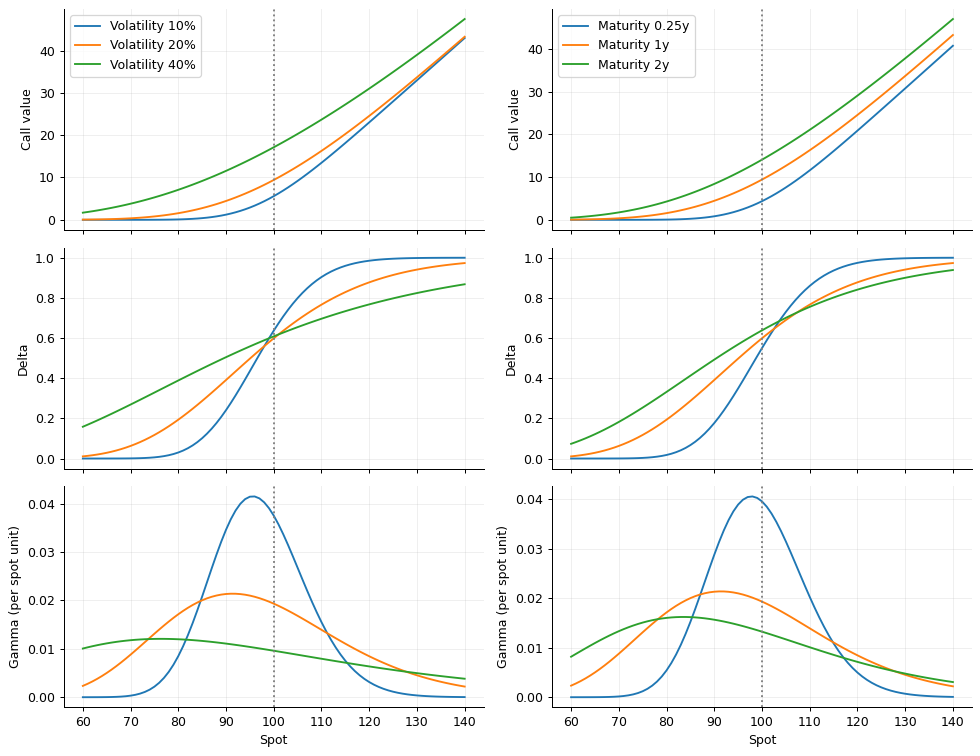

Changed input,Value,Call price,Delta,Gamma
Rate,-0.01,7.513058,0.5199388,0.0199222
Rate,0.03,9.413403,0.5987063,0.01933341
Rate,0.06,10.98955,0.6554217,0.01841351
Dividend,0,9.413403,0.5987063,0.01933341
Dividend,0.02,8.266328,0.5485365,0.01933341


In [4]:
volatility_values = (0.10, 0.20, 0.40)
maturity_values = (0.25, 1.0, 2.0)
rate_values = (-0.01, 0.03, 0.06)
dividend_values = (0.0, 0.02)

fig, axes = plt.subplots(3, 2, figsize=(11, 8.5), sharex=True)
for column, values in enumerate((volatility_values, maturity_values)):
    for value in values:
        model = replace(case.model, volatilities=(value,)) if column == 0 else case.model
        contract = case.contract if column == 0 else replace(case.contract, maturity=value)
        engine = BlackScholesReference(model, contract)
        results = [engine.evaluate(float(s)) for s in spot_grid]
        label = f"Volatility {value:.0%}" if column == 0 else f"Maturity {value:g}y"
        for row, field in enumerate(("call_price", "call_delta", "gamma")):
            axes[row, column].plot(spot_grid, [getattr(v, field) for v in results], label=label)
for row, label in enumerate(("Call value", "Delta", "Gamma (per spot unit)")):
    for column in range(2):
        axes[row, column].set_ylabel(label)
        axes[row, column].axvline(strike, color="0.5", ls=":")
axes[0, 0].legend()
axes[0, 1].legend()
axes[2, 0].set_xlabel("Spot")
axes[2, 1].set_xlabel("Spot")
fig.tight_layout()
plt.show()

rows = []
for name, values in (("Rate", rate_values), ("Dividend", dividend_values)):
    for value in values:
        model = replace(case.model, rate=value) if name == "Rate" else replace(
            case.model, dividend_yields=(value,))
        result = BlackScholesReference(model, case.contract).evaluate(spot)
        rows.append((name, value, result.call_price, result.call_delta, result.gamma))
table(["Changed input", "Value", "Call price", "Delta", "Gamma"], rows)

## 4. Monte Carlo estimates against analytical curves

Error bars are pointwise approximate 95% intervals. Identical seeds across spot values provide matched random draws, so estimates across those points are correlated. A single interval may miss the analytical value without establishing an implementation defect. Gamma remains an analytical reference here.

Spot,Analytical price,MC price,Price SE,Analytical delta,MC delta,Delta SE
80,1.561679,1.543293,0.0168826,0.1933225,0.1915088,0.00149621
100,9.413403,9.389657,0.04441069,0.5987063,0.5998578,0.001849228
120,24.54721,24.51982,0.06961492,0.8773026,0.8770123,0.001344414


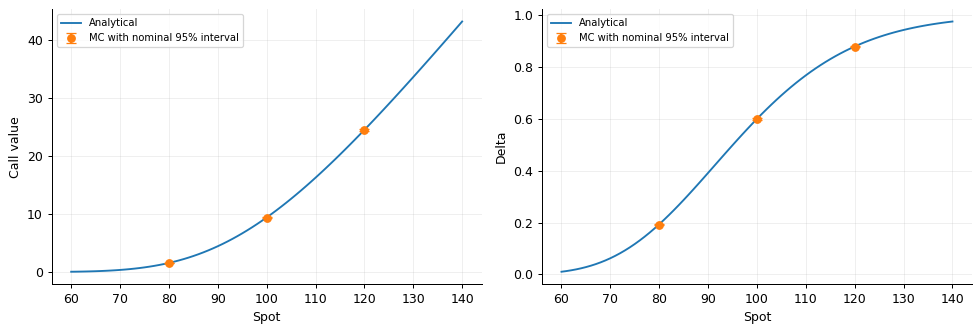

In [5]:
comparison_spots = sorted(set((0.8 * strike, spot, 1.2 * strike)))
comparisons = []
for s in comparison_spots:
    price = pricer.estimate((s,), n_paths=mc_paths, rng=np.random.default_rng(seed))
    delta = pricer.estimate_delta((s,), n_paths=mc_paths, rng=np.random.default_rng(seed),
                                  bump_fraction=bump_fraction)
    exact = reference.evaluate(s)
    comparisons.append((s, price, delta, exact))
table(["Spot", "Analytical price", "MC price", "Price SE", "Analytical delta", "MC delta", "Delta SE"],
      [(s, e.call_price, p.price_estimate, p.standard_error, e.call_delta,
        d.pathwise.estimate, d.pathwise.standard_error) for s, p, d, e in comparisons])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(spot_grid, [v.call_price for v in curve], label="Analytical")
axes[1].plot(spot_grid, [v.call_delta for v in curve], label="Analytical")
for ax, quantity in zip(axes, ("price", "delta")):
    means = [p.price_estimate if quantity == "price" else d.pathwise.estimate
             for s, p, d, e in comparisons]
    errors = [1.95996398454 * (p.standard_error if quantity == "price" else d.pathwise.standard_error)
              for s, p, d, e in comparisons]
    ax.errorbar(comparison_spots, means, yerr=errors, fmt="o", capsize=4,
                color="C1", label="MC with nominal 95% interval")
    ax.set(xlabel="Spot", ylabel="Call value" if quantity == "price" else "Delta")
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## 5. Sample count and seed variation

Standard error is expected to scale as $N^{-1/2}$. The dashed guides are anchored at the first measured point; they are not fitted convergence claims. RMS errors from four seeds are noisy summaries. Individual realised errors need not decrease monotonically as sample count increases.

Samples,Mean MC price,Price RMS error,Mean price SE,Delta RMS error,Mean delta SE
1000,9.632195,0.4508321,0.4596108,0.01592718,0.01866222
10000,9.41804,0.1351961,0.1412066,0.007116857,0.00585949
100000,9.407147,0.03369794,0.04459171,0.00290543,0.001851327


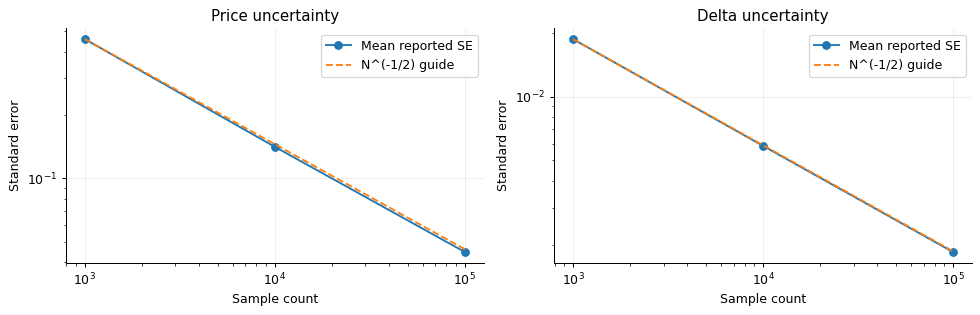

In [6]:
convergence = []
for count in sample_counts:
    prices, deltas = [], []
    for study_seed in study_seeds:
        prices.append(pricer.estimate((spot,), n_paths=count,
                      rng=np.random.default_rng(study_seed)))
        deltas.append(pricer.estimate_delta((spot,), n_paths=count,
                      rng=np.random.default_rng(study_seed), bump_fraction=bump_fraction))
    convergence.append((count,
        float(np.mean([v.price_estimate for v in prices])),
        float(np.sqrt(np.mean([(v.price_estimate - base.call_price)**2 for v in prices]))),
        float(np.mean([v.standard_error for v in prices])),
        float(np.sqrt(np.mean([(v.pathwise.estimate - base.call_delta)**2 for v in deltas]))),
        float(np.mean([v.pathwise.standard_error for v in deltas]))))
table(["Samples", "Mean MC price", "Price RMS error", "Mean price SE", "Delta RMS error", "Mean delta SE"], convergence)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
counts = np.array([row[0] for row in convergence])
for ax, index, title in zip(axes, (3, 5), ("Price uncertainty", "Delta uncertainty")):
    errors = np.array([row[index] for row in convergence])
    ax.loglog(counts, errors, "o-", label="Mean reported SE")
    ax.loglog(counts, errors[0] * np.sqrt(counts[0] / counts), "--", label="N^(-1/2) guide")
    ax.set(xlabel="Sample count", ylabel="Standard error", title=title)
    ax.legend()
fig.tight_layout()
plt.show()

## 6. Bump size and paired delta error

Pathwise and central-bump deltas share noise. Their discrepancy must use paired contributions, not an independent-error formula. A finite bump targets a price secant and introduces bias. The analytical derivative-minus-secant is therefore shown alongside the measured paired difference. Small crossing counts can make a normal interval unreliable; very small bumps also introduce rounding error.

Relative bump,Absolute bump,Pathwise,Central bump,Paired gap,Paired SE,Crossings
0.02,2,0.5998578,0.5990007,0.0008570958,0.0002502561,7991
0.01,1,0.5998578,0.5994556,0.000402132,0.0001769911,3969
0.005,0.5,0.5998578,0.5997778,7.999291e-05,0.0001261742,1963
0.001,0.1,0.5998578,0.5998742,-1.639589e-05,5.798102e-05,424


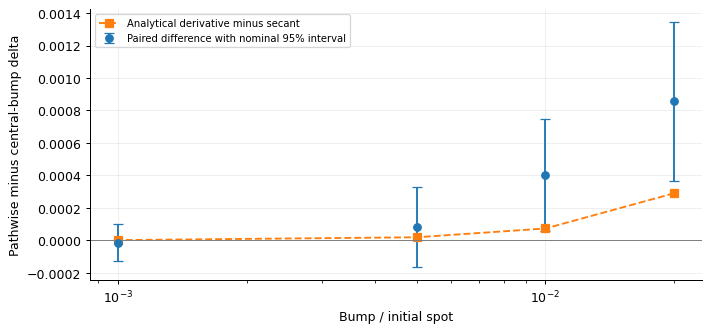

In [7]:
bump_fractions = (0.02, 0.01, 0.005, 0.001)
bump_results, expected_gaps = [], []
for fraction in bump_fractions:
    result = pricer.estimate_delta((spot,), n_paths=mc_paths,
             rng=np.random.default_rng(seed), bump_fraction=fraction)
    h = result.bump_size
    secant = (reference.evaluate(spot + h).call_price -
              reference.evaluate(spot - h).call_price) / (2 * h)
    bump_results.append(result)
    expected_gaps.append(base.call_delta - secant)
table(["Relative bump", "Absolute bump", "Pathwise", "Central bump", "Paired gap", "Paired SE", "Crossings"],
      [(v.bump_fraction, v.bump_size, v.pathwise.estimate, v.central_bump.estimate,
        v.paired_difference.estimate, v.paired_difference.standard_error,
        v.bump_crossing_count) for v in bump_results])
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.errorbar(bump_fractions, [v.paired_difference.estimate for v in bump_results],
    yerr=[1.95996398454 * v.paired_difference.standard_error for v in bump_results],
    fmt="o", capsize=4, label="Paired difference with nominal 95% interval")
ax.plot(bump_fractions, expected_gaps, "s--", label="Analytical derivative minus secant")
ax.axhline(0, color="0.5", lw=0.8)
ax.set(xscale="log", xlabel="Bump / initial spot", ylabel="Pathwise minus central-bump delta")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Interpretation

- Financial parameter changes alter the option being valued; sample-count and bump changes alter numerical uncertainty or bias.
- The analytical price and Greeks are independent references for these simulation calculations.
- Confidence intervals describe sampling uncertainty under the model and are approximate. Inspect positive-payoff and bump-crossing counts for rare-event diagnostics.
- Run all cells after changing configuration to avoid mixing results from different cases. The finite-difference comparison will extend this notebook when its reference is implemented.